# 🚚 Logistics — Where Are Packages Getting Stuck?
**Project:** DS_Day01_24 | **Industry:** Logistics & Supply Chain | **Algorithm:** Random Forest

**Objective:** Find where shipments lose time in the supply chain (pickup → sorting → dispatch → delivery), which warehouses and transport modes cause the most delays, whether volume affects processing time, and recommend operational improvements.

**Notebook flow**
1. Dataset creation (synthetic)
2. Data cleaning & validation
3. Stage-time calculation
4. Exploratory data analysis
5. Warehouse, transport-mode & volume analysis
6. Bottleneck (process) analysis
7. Four visualisations (incl. complete logistics journey)
8. Random Forest model + evaluation
9. Key insights & action plan

## 1. Setup & Synthetic Dataset Creation
No dataset was provided, so a realistic one is generated (1,000 shipments, Jan–Mar 2026). Warehouse **WH-C** is deliberately built to be slower, and delay probability rises with transit time.

In [3]:
import pandas as pd
import numpy as np

np.random.seed(42)
n = 1000

In [4]:
# Basic information
origins = ["Chennai", "Coimbatore", "Bangalore", "Hyderabad", "Mumbai"]
destinations = ["Chennai", "Coimbatore", "Bangalore", "Hyderabad", "Mumbai"]
warehouses = ["WH-A", "WH-B", "WH-C", "WH-D"]
transport_modes = ["Truck", "Train", "Air"]

df = pd.DataFrame({
    "Shipment_ID": range(1, n + 1),
    "Origin": np.random.choice(origins, n),
    "Destination": np.random.choice(destinations, n),
    "Warehouse": np.random.choice(
        warehouses, n, p=[0.30, 0.30, 0.25, 0.15]
    ),
    "Transport_Mode": np.random.choice(
        transport_modes, n, p=[0.60, 0.25, 0.15]
    )
})

# Transit time based on transport mode
df["Transit_Time"] = [
    np.random.randint(5, 20) if mode == "Air"
    else np.random.randint(15, 35) if mode == "Train"
    else np.random.randint(20, 50)
    for mode in df["Transport_Mode"]
]

# Warehouse processing delays
warehouse_delay = {
    "WH-A": 2,
    "WH-B": 4,
    "WH-C": 7,
    "WH-D": 3
}

df["Sorting_Hours"] = [
    np.random.randint(2, 6) + warehouse_delay[w]
    for w in df["Warehouse"]
]

df["Dispatch_Hours"] = [
    np.random.randint(2, 7) + warehouse_delay[w]
    for w in df["Warehouse"]
]

# Pickup time
start_date = pd.Timestamp("2026-01-01")

df["Pickup_Time"] = [
    start_date + pd.Timedelta(hours=int(x))
    for x in np.random.randint(0, 24 * 90, n)
]

# Sorting and dispatch timestamps
df["Sorting_Time"] = (
    df["Pickup_Time"] +
    pd.to_timedelta(df["Sorting_Hours"], unit="h")
)

df["Dispatch_Time"] = (
    df["Sorting_Time"] +
    pd.to_timedelta(df["Dispatch_Hours"], unit="h")
)

# Delivery timestamp
df["Delivery_Time"] = (
    df["Dispatch_Time"] +
    pd.to_timedelta(df["Transit_Time"], unit="h")
)

# Create realistic delivery delays
delay_probability = (
    0.05
    + df["Transit_Time"] / 200
    + df["Warehouse"].map({
        "WH-A": 0.02,
        "WH-B": 0.05,
        "WH-C": 0.12,
        "WH-D": 0.04
    })
)

delay_probability = delay_probability.clip(0, 0.8)

df["Delivery_Status"] = np.where(
    np.random.random(n) < delay_probability,
    "Delayed",
    "Delivered"
)

# Make delayed shipments actually take longer
delay_extra = np.where(
    df["Delivery_Status"] == "Delayed",
    np.random.randint(8, 30, n),
    0
)

df["Delivery_Time"] += pd.to_timedelta(delay_extra, unit="h")

# Save final dataset
df = df[
    [
        "Shipment_ID",
        "Origin",
        "Destination",
        "Warehouse",
        "Pickup_Time",
        "Sorting_Time",
        "Dispatch_Time",
        "Delivery_Time",
        "Transit_Time",
        "Transport_Mode",
        "Delivery_Status"
    ]
]

df.to_csv("logistics.csv", index=False)

print("Dataset created successfully!")
print("Shape:", df.shape)
df.head()

Dataset created successfully!
Shape: (1000, 11)


,Shipment_ID,Origin,Destination,Warehouse,Pickup_Time,Sorting_Time,Dispatch_Time,Delivery_Time,Transit_Time,Transport_Mode,Delivery_Status
0,1,Hyderabad,Hyderabad,WH-C,2026-02-27 22:00:00,2026-02-28 07:00:00,2026-02-28 16:00:00,2026-03-02 03:00:00,35,Truck,Delivered
1,2,Mumbai,Hyderabad,WH-B,2026-02-17 02:00:00,2026-02-17 11:00:00,2026-02-17 18:00:00,2026-02-18 17:00:00,23,Train,Delivered
2,3,Bangalore,Hyderabad,WH-A,2026-02-04 18:00:00,2026-02-04 22:00:00,2026-02-05 05:00:00,2026-02-06 12:00:00,31,Truck,Delivered
3,4,Mumbai,Hyderabad,WH-B,2026-01-10 10:00:00,2026-01-10 18:00:00,2026-01-11 00:00:00,2026-01-11 16:00:00,16,Air,Delivered
4,5,Mumbai,Mumbai,WH-B,2026-01-19 09:00:00,2026-01-19 18:00:00,2026-01-20 04:00:00,2026-01-22 06:00:00,25,Truck,Delayed


## 2. Data Cleaning & Validation
Checks: missing values, duplicates, datatype conversion, timestamp order, plus extra sanity checks (valid categories, origin = destination, outliers).

In [5]:
# Check basic information
print("Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

# Convert timestamp columns to datetime
time_cols = [
    "Pickup_Time",
    "Sorting_Time",
    "Dispatch_Time",
    "Delivery_Time"
]

for col in time_cols:
    df[col] = pd.to_datetime(df[col])

# Check for invalid timestamp order
invalid_rows = (
    (df["Sorting_Time"] < df["Pickup_Time"]) |
    (df["Dispatch_Time"] < df["Sorting_Time"]) |
    (df["Delivery_Time"] < df["Dispatch_Time"])
).sum()

print("\nInvalid Timestamp Rows:", invalid_rows)

# Remove duplicates if any
df.drop_duplicates(inplace=True)

print("\nFinal Shape:", df.shape)

Shape: (1000, 11)

Missing Values:
Shipment_ID        0
Origin             0
Destination        0
Warehouse          0
Pickup_Time        0
Sorting_Time       0
Dispatch_Time      0
Delivery_Time      0
Transit_Time       0
Transport_Mode     0
Delivery_Status    0
dtype: int64

Duplicate Rows: 0

Invalid Timestamp Rows: 0

Final Shape: (1000, 11)


In [6]:
# Extra validation checks
print("Unique Shipment IDs:", df["Shipment_ID"].is_unique)
print("Invalid warehouses :", (~df["Warehouse"].isin(["WH-A","WH-B","WH-C","WH-D"])).sum())
print("Invalid modes      :", (~df["Transport_Mode"].isin(["Truck","Train","Air"])).sum())
print("Negative transit   :", (df["Transit_Time"] <= 0).sum())

# Shipments where origin == destination (not a real inter-city move)
same_city = (df["Origin"] == df["Destination"])
print("\nShipments with Origin == Destination:", same_city.sum(), f"({same_city.mean()*100:.1f}%)")

# Decision: drop them, since they do not represent a real origin->destination journey
df = df[~same_city].reset_index(drop=True)
print("Shape after removing same-city shipments:", df.shape)

Unique Shipment IDs: True
Invalid warehouses : 0
Invalid modes      : 0
Negative transit   : 0

Shipments with Origin == Destination: 187 (18.7%)
Shape after removing same-city shipments: (813, 11)


## 3. Time Spent at Each Stage
Stage durations (hours): **Sorting** = Sorting − Pickup, **Dispatch** = Dispatch − Sorting, **Delivery/Transit** = Delivery − Dispatch, **Total** = Delivery − Pickup. We also add **Processing_Hours** (Sorting + Dispatch) = time the parcel spends *inside the warehouse*.

In [7]:
# Calculate time spent at each stage in hours

df["Sorting_Hours"] = (
    df["Sorting_Time"] - df["Pickup_Time"]
).dt.total_seconds() / 3600

df["Dispatch_Hours"] = (
    df["Dispatch_Time"] - df["Sorting_Time"]
).dt.total_seconds() / 3600

df["Delivery_Hours"] = (
    df["Delivery_Time"] - df["Dispatch_Time"]
).dt.total_seconds() / 3600

df["Total_Hours"] = (
    df["Delivery_Time"] - df["Pickup_Time"]
).dt.total_seconds() / 3600

# Display the result
df[
    [
        "Shipment_ID",
        "Sorting_Hours",
        "Dispatch_Hours",
        "Delivery_Hours",
        "Total_Hours"
    ]
].head()

,Shipment_ID,Sorting_Hours,Dispatch_Hours,Delivery_Hours,Total_Hours
0,2,9.0,7.0,23.0,39.0
1,3,4.0,7.0,31.0,42.0
2,4,8.0,6.0,16.0,30.0
3,6,8.0,7.0,38.0,53.0
4,7,6.0,6.0,66.0,78.0


In [8]:
# Warehouse processing time = time spent inside the warehouse (sorting + dispatch)
df["Processing_Hours"] = df["Sorting_Hours"] + df["Dispatch_Hours"]

# Extra time-based features
df["Pickup_Hour"] = df["Pickup_Time"].dt.hour
df["Pickup_DayOfWeek"] = df["Pickup_Time"].dt.dayofweek
df["Pickup_Date"] = df["Pickup_Time"].dt.date
df["Is_Delayed"] = (df["Delivery_Status"] == "Delayed").astype(int)

# Outlier check on Total_Hours using the IQR rule
q1, q3 = df["Total_Hours"].quantile([0.25, 0.75])
iqr = q3 - q1
outliers = ((df["Total_Hours"] < q1 - 1.5*iqr) | (df["Total_Hours"] > q3 + 1.5*iqr)).sum()
print("Outliers in Total_Hours (IQR rule):", outliers, "-> kept (they are genuine delayed shipments)")
df[["Shipment_ID","Sorting_Hours","Dispatch_Hours","Processing_Hours","Delivery_Hours","Total_Hours"]].head()

Outliers in Total_Hours (IQR rule): 4 -> kept (they are genuine delayed shipments)


,Shipment_ID,Sorting_Hours,Dispatch_Hours,Processing_Hours,Delivery_Hours,Total_Hours
0,2,9.0,7.0,16.0,23.0,39.0
1,3,4.0,7.0,11.0,31.0,42.0
2,4,8.0,6.0,14.0,16.0,30.0
3,6,8.0,7.0,15.0,38.0,53.0
4,7,6.0,6.0,12.0,66.0,78.0


## 4. Exploratory Data Analysis (Descriptive Statistics)

In [9]:
print("=== DESCRIPTIVE STATISTICS ===")
print(df[[
    "Transit_Time",
    "Sorting_Hours",
    "Dispatch_Hours",
    "Delivery_Hours",
    "Total_Hours"
]].describe())

print("\n=== DELIVERY STATUS ===")
print(df["Delivery_Status"].value_counts())

print("\n=== WAREHOUSE ===")
print(df["Warehouse"].value_counts())

print("\n=== TRANSPORT MODE ===")
print(df["Transport_Mode"].value_counts())

=== DESCRIPTIVE STATISTICS ===
       Transit_Time  Sorting_Hours  Dispatch_Hours  Delivery_Hours  \
count    813.000000     813.000000      813.000000      813.000000   
mean      28.660517       7.521525        7.987700       33.527675   
std       11.012437       2.273989        2.428758       14.775355   
min        5.000000       4.000000        4.000000        5.000000   
25%       21.000000       6.000000        6.000000       23.000000   
50%       29.000000       7.000000        8.000000       32.000000   
75%       37.000000       9.000000       10.000000       43.000000   
max       49.000000      12.000000       13.000000       77.000000   

       Total_Hours  
count   813.000000  
mean     49.036900  
std      15.759542  
min      15.000000  
25%      37.000000  
50%      48.000000  
75%      59.000000  
max      99.000000  

=== DELIVERY STATUS ===
Delivery_Status
Delivered    597
Delayed      216
Name: count, dtype: int64

=== WAREHOUSE ===
Warehouse
WH-B    242
WH-A   

In [10]:
print("Delay rate overall: {:.1f}%".format(df["Is_Delayed"].mean()*100))

print("\n=== Average stage time by Delivery_Status (hours) ===")
print(df.groupby("Delivery_Status")[["Sorting_Hours","Dispatch_Hours","Delivery_Hours","Total_Hours"]].mean().round(2))

print("\n=== Delay rate by Origin -> Destination (top 5 routes) ===")
route = df.groupby(["Origin","Destination"]).agg(Shipments=("Is_Delayed","size"), Delay_Rate=("Is_Delayed","mean"))
route["Delay_Rate"] = (route["Delay_Rate"]*100).round(1)
print(route[route["Shipments"]>=20].sort_values("Delay_Rate", ascending=False).head(5))

Delay rate overall: 26.6%

=== Average stage time by Delivery_Status (hours) ===
                 Sorting_Hours  Dispatch_Hours  Delivery_Hours  Total_Hours
Delivery_Status                                                            
Delayed                   7.90            8.41           49.13        65.44
Delivered                 7.38            7.83           27.88        43.10

=== Delay rate by Origin -> Destination (top 5 routes) ===
                       Shipments  Delay_Rate
Origin    Destination                       
Hyderabad Coimbatore          44        40.9
Bangalore Chennai             31        38.7
          Coimbatore          40        37.5
Mumbai    Chennai             46        34.8
          Coimbatore          38        31.6


## 5. Warehouse, Transport Mode & Volume Analysis

### 5.1 Which warehouses contribute most to delays?

In [11]:
warehouse_analysis = df.groupby("Warehouse").agg(
    Shipments=("Shipment_ID", "count"),
    Delayed=("Delivery_Status", lambda x: (x == "Delayed").sum()),
    Avg_Processing_Time=("Total_Hours", "mean")
)

warehouse_analysis["Delay_Rate"] = (
    warehouse_analysis["Delayed"] /
    warehouse_analysis["Shipments"] * 100
)

warehouse_analysis = warehouse_analysis.sort_values(
    "Delay_Rate",
    ascending=False
)

warehouse_analysis

,Shipments,Delayed,Avg_Processing_Time,Delay_Rate
Warehouse,,,,
WH-C,209,67,56.956938,32.057416
WH-B,242,69,49.185950,28.512397
WH-D,120,31,45.000000,25.833333
WH-A,242,49,44.049587,20.247934


In [12]:
# Better view: share of ALL delays + warehouse-only processing time (sorting + dispatch)
wh = df.groupby("Warehouse").agg(
    Shipments=("Shipment_ID","count"),
    Delayed=("Is_Delayed","sum"),
    Avg_Sorting=("Sorting_Hours","mean"),
    Avg_Dispatch=("Dispatch_Hours","mean"),
    Avg_Processing=("Processing_Hours","mean")
)
wh["Delay_Rate_%"] = wh["Delayed"]/wh["Shipments"]*100
wh["Share_of_All_Delays_%"] = wh["Delayed"]/wh["Delayed"].sum()*100
wh.sort_values("Delay_Rate_%", ascending=False).round(2)

,Shipments,Delayed,Avg_Sorting,Avg_Dispatch,Avg_Processing,Delay_Rate_%,Share_of_All_Delays_%
Warehouse,,,,,,,
WH-C,209,67,10.58,11.03,21.61,32.06,31.02
WH-B,242,69,7.55,8.02,15.57,28.51,31.94
WH-D,120,31,6.52,6.88,13.41,25.83,14.35
WH-A,242,49,5.35,5.88,11.22,20.25,22.69


### 5.2 Comparing transport modes

In [13]:
transport_analysis = df.groupby("Transport_Mode").agg(
    Shipments=("Shipment_ID", "count"),
    Avg_Transit_Time=("Transit_Time", "mean"),
    Avg_Processing_Time=("Total_Hours", "mean"),
    Delayed=("Delivery_Status", lambda x: (x == "Delayed").sum())
)

transport_analysis["Delay_Rate"] = (
    transport_analysis["Delayed"] /
    transport_analysis["Shipments"] * 100
)

print("Transport Mode Analysis")
print(transport_analysis.sort_values("Avg_Processing_Time"))

print("\nFastest Transport Mode:")
print(transport_analysis["Avg_Processing_Time"].idxmin())

print("\nHighest Delay Rate:")
print(transport_analysis["Delay_Rate"].idxmax())

Transport Mode Analysis
                Shipments  Avg_Transit_Time  Avg_Processing_Time  Delayed  \
Transport_Mode                                                              
Air                   113         11.796460            30.017699       17   
Train                 223         23.838565            43.591928       54   
Truck                 477         34.909853            56.088050      145   

                Delay_Rate  
Transport_Mode              
Air              15.044248  
Train            24.215247  
Truck            30.398323  

Fastest Transport Mode:
Air

Highest Delay Rate:
Truck


### 5.3 Does shipment volume affect processing time?
First the original warehouse-level check (only 4 points, so weak evidence), then a stronger test using **daily volume per warehouse** vs. its average processing time that day.

In [14]:
volume_analysis = df.groupby("Warehouse").agg(
    Shipment_Volume=("Shipment_ID", "count"),
    Avg_Processing_Time=("Total_Hours", "mean")
)

correlation = volume_analysis["Shipment_Volume"].corr(
    volume_analysis["Avg_Processing_Time"]
)

print("Shipment Volume vs Processing Time")
print(volume_analysis)

print("\nCorrelation:", round(correlation, 2))

if correlation > 0.5:
    print("Result: Higher shipment volume is associated with longer processing time.")
elif correlation < -0.5:
    print("Result: Higher shipment volume is associated with shorter processing time.")
else:
    print("Result: There is a weak relationship between shipment volume and processing time.")

Shipment Volume vs Processing Time
           Shipment_Volume  Avg_Processing_Time
Warehouse                                      
WH-A                   242            44.049587
WH-B                   242            49.185950
WH-C                   209            56.956938
WH-D                   120            45.000000

Correlation: 0.19
Result: There is a weak relationship between shipment volume and processing time.


In [15]:
from scipy import stats

# Daily volume per warehouse vs average warehouse processing time that day
daily = df.groupby(["Warehouse","Pickup_Date"]).agg(
    Daily_Volume=("Shipment_ID","count"),
    Avg_Processing=("Processing_Hours","mean")
).reset_index()

r, p = stats.pearsonr(daily["Daily_Volume"], daily["Avg_Processing"])
rho, p_s = stats.spearmanr(daily["Daily_Volume"], daily["Avg_Processing"])
print(f"Pearson  r   = {r:.3f} (p = {p:.3f})")
print(f"Spearman rho = {rho:.3f} (p = {p_s:.3f})")

# Also check within each warehouse (controls for the fact that WH-C is simply slower)
print("\nCorrelation within each warehouse:")
for w, g in daily.groupby("Warehouse"):
    print(f"  {w}: r = {g['Daily_Volume'].corr(g['Avg_Processing']):.3f}  (n = {len(g)} days)")

if p > 0.05:
    print("\nConclusion: NO statistically significant link between volume and processing time.")
    print("=> Delays come from warehouse efficiency (process), not from congestion/volume.")
else:
    print("\nConclusion: volume has a statistically significant effect on processing time.")

Pearson  r   = -0.018 (p = 0.753)
Spearman rho = -0.051 (p = 0.368)

Correlation within each warehouse:
  WH-A: r = -0.134  (n = 82 days)
  WH-B: r = -0.104  (n = 83 days)
  WH-C: r = 0.077  (n = 79 days)
  WH-D: r = -0.211  (n = 67 days)

Conclusion: NO statistically significant link between volume and processing time.
=> Delays come from warehouse efficiency (process), not from congestion/volume.


## 6. Bottleneck Identification (Process Analysis)
We treat the journey as a 3-stage process: **Sorting → Dispatch → Transit**. A bottleneck is the stage that consumes the largest share of total time and varies most between warehouses/modes.

In [16]:
stage_cols = ["Sorting_Hours","Dispatch_Hours","Delivery_Hours"]

# Overall stage share
overall = df[stage_cols].mean()
share = (overall/overall.sum()*100).round(1)
print("Average hours per stage:\n", overall.round(2))
print("\nShare of total journey time (%):\n", share)

# Stage time by warehouse
stage_wh = df.groupby("Warehouse")[stage_cols].mean().round(2)
stage_wh["Processing (Sort+Dispatch)"] = stage_wh["Sorting_Hours"] + stage_wh["Dispatch_Hours"]
print("\nStage time by warehouse (hours):")
print(stage_wh)

# Bottleneck score: how much slower each warehouse is than the network average, per stage
network_avg = df[["Sorting_Hours","Dispatch_Hours"]].mean()
gap = (df.groupby("Warehouse")[["Sorting_Hours","Dispatch_Hours"]].mean() - network_avg).round(2)
gap.columns = ["Sorting gap vs avg (h)", "Dispatch gap vs avg (h)"]
print("\nGap vs network average (positive = slower than average):")
print(gap)

# Share of shipments that exceed the 75th percentile of warehouse processing time
thr = df["Processing_Hours"].quantile(0.75)
slow = df.assign(Slow=df["Processing_Hours"] > thr).groupby("Warehouse")["Slow"].mean().mul(100).round(1)
print(f"\n% of shipments with slow processing (> {thr:.0f} h, top 25%) by warehouse:")
print(slow)

worst = stage_wh["Processing (Sort+Dispatch)"].idxmax()
print(f"\n>>> PRIMARY BOTTLENECK: {worst} (both sorting and dispatch are the slowest)")
print(">>> SECONDARY BOTTLENECK: Road (Truck) transit stage — the longest stage of the whole journey")

Average hours per stage:
 Sorting_Hours      7.52
Dispatch_Hours     7.99
Delivery_Hours    33.53
dtype: float64

Share of total journey time (%):
 Sorting_Hours     15.3
Dispatch_Hours    16.3
Delivery_Hours    68.4
dtype: float64

Stage time by warehouse (hours):
           Sorting_Hours  Dispatch_Hours  Delivery_Hours  \
Warehouse                                                  
WH-A                5.35            5.88           32.83   
WH-B                7.55            8.02           33.62   
WH-C               10.58           11.03           35.34   
WH-D                6.52            6.88           31.59   

           Processing (Sort+Dispatch)  
Warehouse                              
WH-A                            11.23  
WH-B                            15.57  
WH-C                            21.61  
WH-D                            13.40  

Gap vs network average (positive = slower than average):
           Sorting gap vs avg (h)  Dispatch gap vs avg (h)
Warehouse       

In [17]:
# Lost-time analysis: extra hours a delayed shipment takes vs. an on-time one, per stage
lost = df.groupby("Delivery_Status")[["Sorting_Hours","Dispatch_Hours","Delivery_Hours"]].mean().round(2)
lost.loc["Extra hours when delayed"] = (lost.loc["Delayed"] - lost.loc["Delivered"]).round(2)
lost

,Sorting_Hours,Dispatch_Hours,Delivery_Hours
Delivery_Status,,,
Delayed,7.90,8.41,49.13
Delivered,7.38,7.83,27.88
Extra hours when delayed,0.52,0.58,21.25


## 7. Visualisations

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
colors_wh = {"WH-A":"#4C9F70","WH-B":"#4C78A8","WH-C":"#E45756","WH-D":"#F2A541"}

### Visualisation 1 — Delay Rate by Warehouse and by Transport Mode

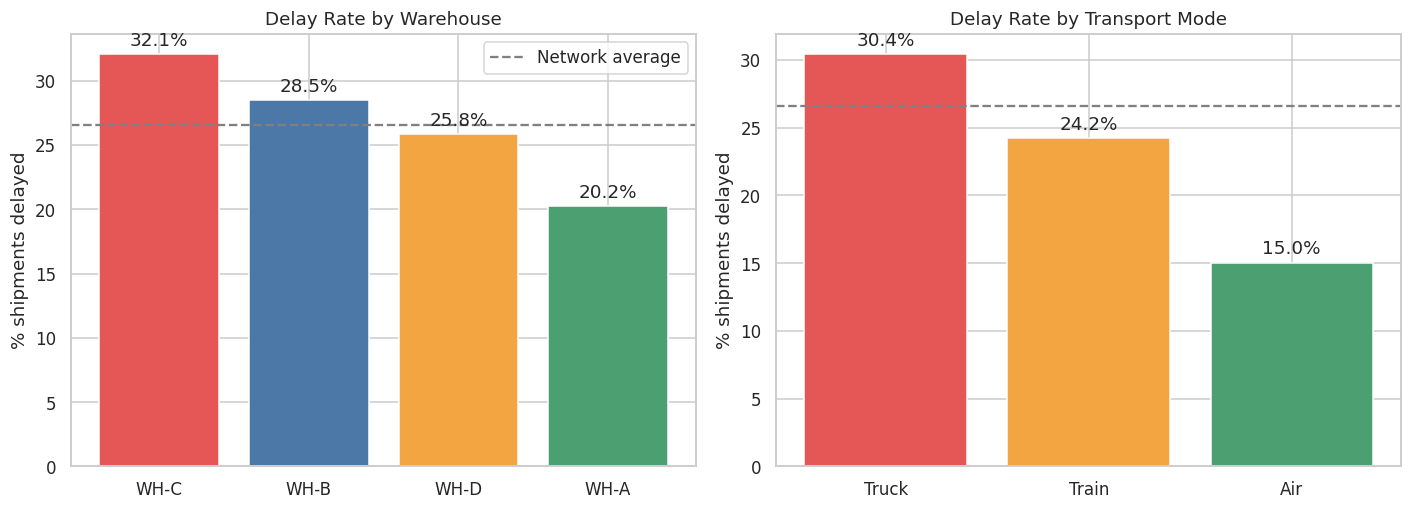

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# (a) Warehouse
d = df.groupby("Warehouse")["Is_Delayed"].mean().mul(100).sort_values(ascending=False)
bars = axes[0].bar(d.index, d.values, color=[colors_wh[w] for w in d.index])
axes[0].axhline(df["Is_Delayed"].mean()*100, ls="--", color="gray", label="Network average")
axes[0].bar_label(bars, fmt="%.1f%%", padding=3)
axes[0].set_title("Delay Rate by Warehouse"); axes[0].set_ylabel("% shipments delayed"); axes[0].legend()

# (b) Transport mode
m = df.groupby("Transport_Mode")["Is_Delayed"].mean().mul(100).sort_values(ascending=False)
bars = axes[1].bar(m.index, m.values, color=["#E45756","#F2A541","#4C9F70"])
axes[1].axhline(df["Is_Delayed"].mean()*100, ls="--", color="gray")
axes[1].bar_label(bars, fmt="%.1f%%", padding=3)
axes[1].set_title("Delay Rate by Transport Mode"); axes[1].set_ylabel("% shipments delayed")

plt.tight_layout(); plt.show()

### Visualisation 2 — Time Spent at Each Stage per Warehouse (Bottleneck View)

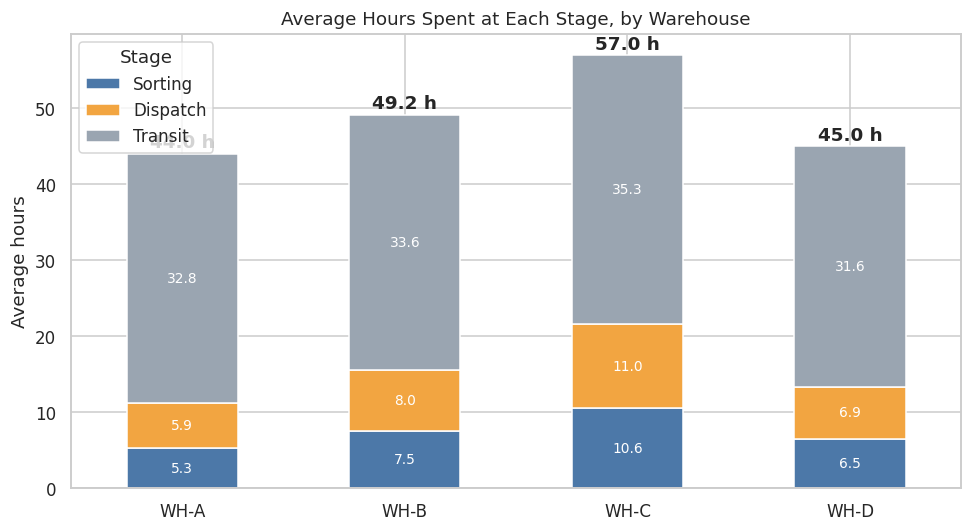

In [20]:
stage = df.groupby("Warehouse")[["Sorting_Hours","Dispatch_Hours","Delivery_Hours"]].mean()
stage.columns = ["Sorting","Dispatch","Transit"]

ax = stage.plot(kind="bar", stacked=True, figsize=(9, 5),
                color=["#4C78A8","#F2A541","#9AA5B1"], edgecolor="white")
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f", label_type="center", color="white", fontsize=9)
totals = stage.sum(axis=1)
for i, t in enumerate(totals):
    ax.text(i, t+0.8, f"{t:.1f} h", ha="center", fontweight="bold")
ax.set_title("Average Hours Spent at Each Stage, by Warehouse")
ax.set_ylabel("Average hours"); ax.set_xlabel("")
plt.xticks(rotation=0); plt.legend(title="Stage"); plt.tight_layout(); plt.show()

### Visualisation 3 — Does Shipment Volume Affect Processing Time?

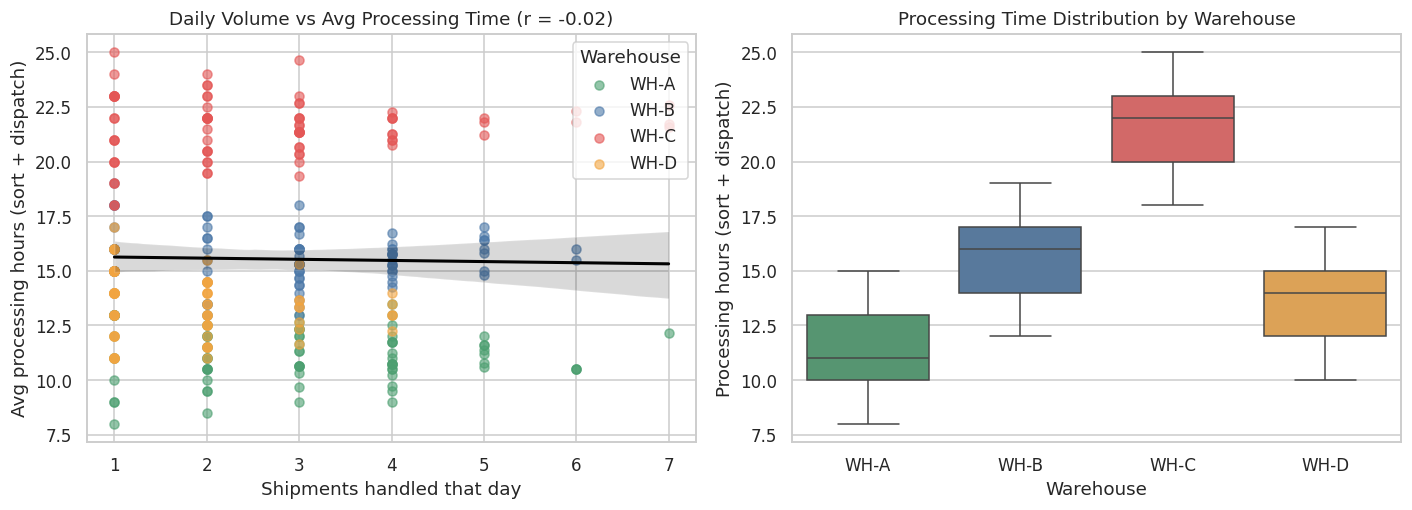

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# (a) Daily volume vs processing time, coloured by warehouse
for w, g in daily.groupby("Warehouse"):
    axes[0].scatter(g["Daily_Volume"], g["Avg_Processing"], alpha=0.6, label=w, color=colors_wh[w], s=35)
sns.regplot(data=daily, x="Daily_Volume", y="Avg_Processing", scatter=False, ax=axes[0], color="black", line_kws={"lw":2})
axes[0].set_title(f"Daily Volume vs Avg Processing Time (r = {r:.2f})")
axes[0].set_xlabel("Shipments handled that day"); axes[0].set_ylabel("Avg processing hours (sort + dispatch)")
axes[0].legend(title="Warehouse")

# (b) Processing-time distribution per warehouse
sns.boxplot(data=df, x="Warehouse", y="Processing_Hours", order=["WH-A","WH-B","WH-C","WH-D"],
            hue="Warehouse", palette=colors_wh, legend=False, ax=axes[1])
axes[1].set_title("Processing Time Distribution by Warehouse")
axes[1].set_ylabel("Processing hours (sort + dispatch)")

plt.tight_layout(); plt.show()

### Visualisation 4 — The Complete Logistics Journey
Average timeline of a shipment from **pickup → sorting → dispatch → delivery** for each warehouse (top), and on-time vs delayed shipments (bottom).

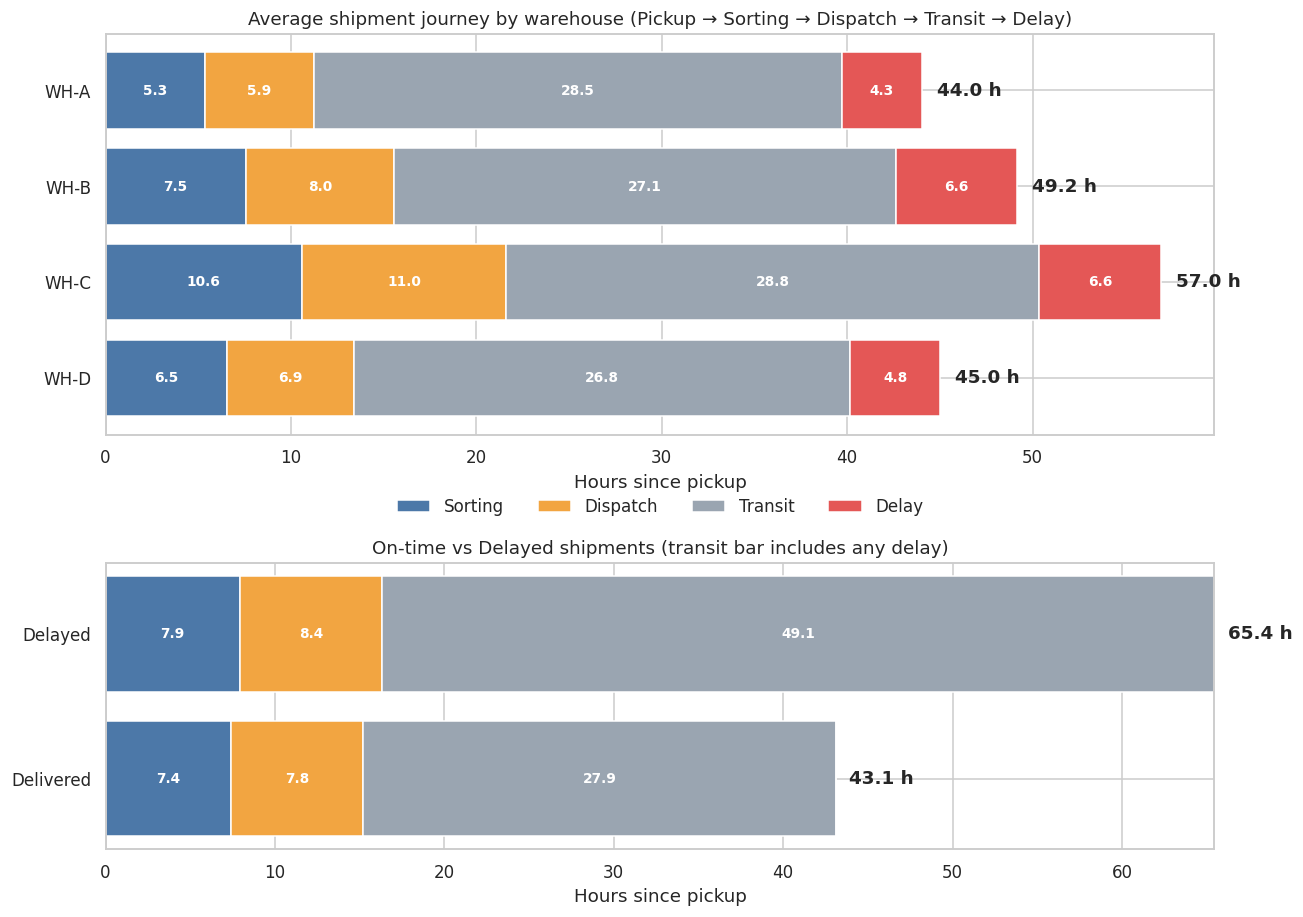

In [22]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8.5), gridspec_kw={"height_ratios":[1.4, 1]})
stage_colors = {"Sorting":"#4C78A8", "Dispatch":"#F2A541", "Transit":"#9AA5B1", "Delay":"#E45756"}

def journey(ax, groups, title):
    labels = []
    for i, (name, g) in enumerate(groups):
        s, dsp = g["Sorting_Hours"].mean(), g["Dispatch_Hours"].mean()
        t_on = g.loc[g["Is_Delayed"]==0, "Delivery_Hours"].mean() if (0 < g["Is_Delayed"].mean() < 1) else g["Delivery_Hours"].mean()
        # extra delay hours averaged across ALL shipments in group (expected delay)
        extra = g["Delivery_Hours"].mean() - t_on
        left = 0
        for lab, val in [("Sorting", s), ("Dispatch", dsp), ("Transit", t_on), ("Delay", extra)]:
            ax.barh(i, val, left=left, color=stage_colors[lab], edgecolor="white", label=lab if i == 0 else None)
            if val > 3:
                ax.text(left+val/2, i, f"{val:.1f}", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
            left += val
        ax.text(left+0.8, i, f"{left:.1f} h", va="center", fontweight="bold")
        labels.append(name)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels); ax.invert_yaxis()
    ax.set_title(title); ax.set_xlabel("Hours since pickup")

wh_groups = [(w, g) for w, g in df.groupby("Warehouse")]
journey(axes[0], wh_groups, "Average shipment journey by warehouse (Pickup → Sorting → Dispatch → Transit → Delay)")
axes[0].legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)

status_groups = [(s, g) for s, g in df.groupby("Delivery_Status")]
journey(axes[1], status_groups, "On-time vs Delayed shipments (transit bar includes any delay)")

plt.tight_layout(); plt.show()

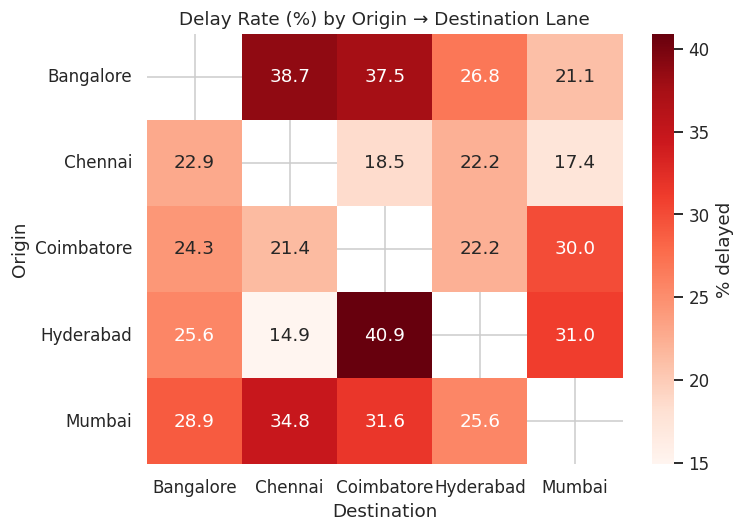

In [23]:
# Bonus: delay-rate heatmap for every Origin -> Destination lane
pivot = df.pivot_table(index="Origin", columns="Destination", values="Is_Delayed", aggfunc="mean") * 100
plt.figure(figsize=(7, 5))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label":"% delayed"})
plt.title("Delay Rate (%) by Origin → Destination Lane")
plt.tight_layout(); plt.show()

## 8. Random Forest Model — Predicting Delayed Shipments
**Goal:** predict whether a shipment will be **Delayed** using only information known *at or before dispatch* (warehouse, transport mode, planned transit time, sorting and dispatch time).

⚠️ **Data-leakage note:** `Delivery_Hours` and `Total_Hours` are deliberately **excluded** because they contain the delay itself and would only be known after delivery.

In [24]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report, roc_curve, ConfusionMatrixDisplay)

# Feature selection: a first run with Origin, Destination, Pickup_Hour and Pickup_DayOfWeek showed
# they behave like noise (CV ROC-AUC 0.575 vs 0.589 without them), so we keep the operational drivers only.
features_cat = ["Warehouse","Transport_Mode"]
features_num = ["Transit_Time","Sorting_Hours","Dispatch_Hours"]

X = pd.get_dummies(df[features_cat + features_num], columns=features_cat, drop_first=False)
y = df["Is_Delayed"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Delay rate  train: {:.1f}%  test: {:.1f}%".format(y_train.mean()*100, y_test.mean()*100))

Train: (650, 10) | Test: (163, 10)
Delay rate  train: 26.6%  test: 26.4%


In [25]:
# Hyper-parameter tuning with 5-fold CV (optimising ROC-AUC because classes are imbalanced)
param_grid = {
    "n_estimators": [200, 400],
    "max_depth": [4, 6, 8, None],
    "min_samples_leaf": [3, 5, 10],
}
grid = GridSearchCV(
    RandomForestClassifier(random_state=42, class_weight="balanced", n_jobs=-1),
    param_grid, cv=StratifiedKFold(5, shuffle=True, random_state=42),
    scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV ROC-AUC: {:.3f}".format(grid.best_score_))

rf = grid.best_estimator_   # the trained Random Forest model

Best parameters: {'max_depth': None, 'min_samples_leaf': 10, 'n_estimators': 200}
Best CV ROC-AUC: 0.594


### 8.1 Model Evaluation

In [26]:
y_pred = rf.predict(X_test)
y_prob = rf.predict_proba(X_test)[:, 1]

results = pd.Series({
    "Accuracy":  accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall":    recall_score(y_test, y_pred),
    "F1-score":  f1_score(y_test, y_pred),
    "ROC-AUC":   roc_auc_score(y_test, y_prob),
}).round(3)
print("=== TEST SET PERFORMANCE ===")
print(results)

print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred, target_names=["Delivered","Delayed"]))

# Baseline: always predict the majority class
base_acc = 1 - y_test.mean()
print(f"Baseline accuracy (always 'Delivered'): {base_acc:.3f}")

# Cross-validated stability check on the full data
cv_auc = cross_val_score(rf, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=1), scoring="roc_auc")
print(f"5-fold CV ROC-AUC: {cv_auc.mean():.3f} ± {cv_auc.std():.3f}")

=== TEST SET PERFORMANCE ===
Accuracy     0.589
Precision    0.293
Recall       0.395
F1-score     0.337
ROC-AUC      0.550
dtype: float64

=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

   Delivered       0.75      0.66      0.70       120
     Delayed       0.29      0.40      0.34        43

    accuracy                           0.59       163
   macro avg       0.52      0.53      0.52       163
weighted avg       0.63      0.59      0.61       163

Baseline accuracy (always 'Delivered'): 0.736
5-fold CV ROC-AUC: 0.594 ± 0.046


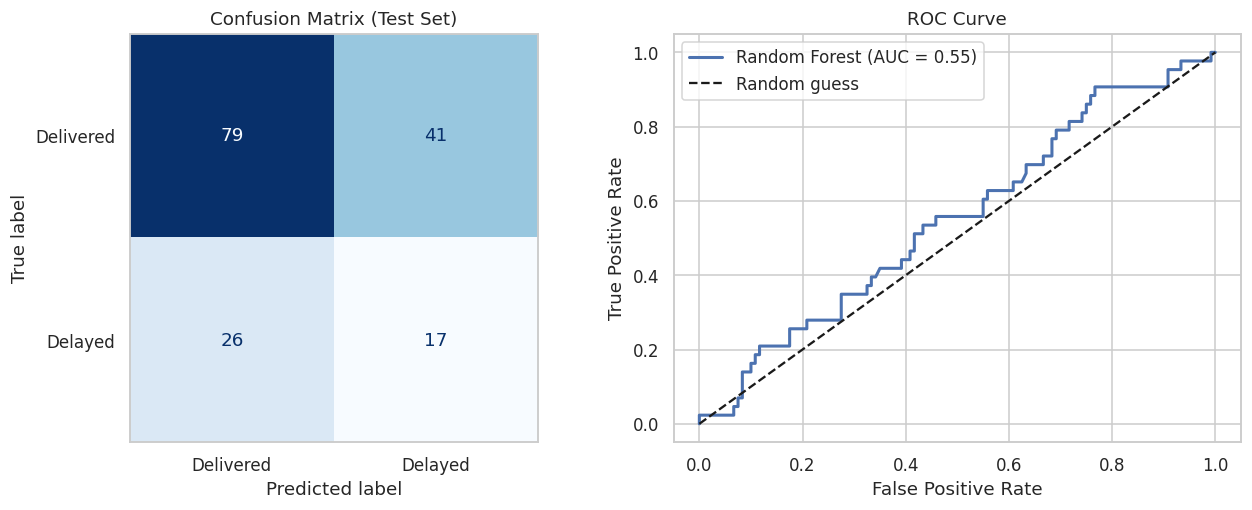

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Confusion matrix
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["Delivered","Delayed"]).plot(
    ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion Matrix (Test Set)"); axes[0].grid(False)

# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, lw=2, label=f"Random Forest (AUC = {roc_auc_score(y_test, y_prob):.2f})")
axes[1].plot([0,1],[0,1],"k--", label="Random guess")
axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC Curve"); axes[1].legend()
plt.tight_layout(); plt.show()

### 8.2 What drives delays? (Feature Importance)

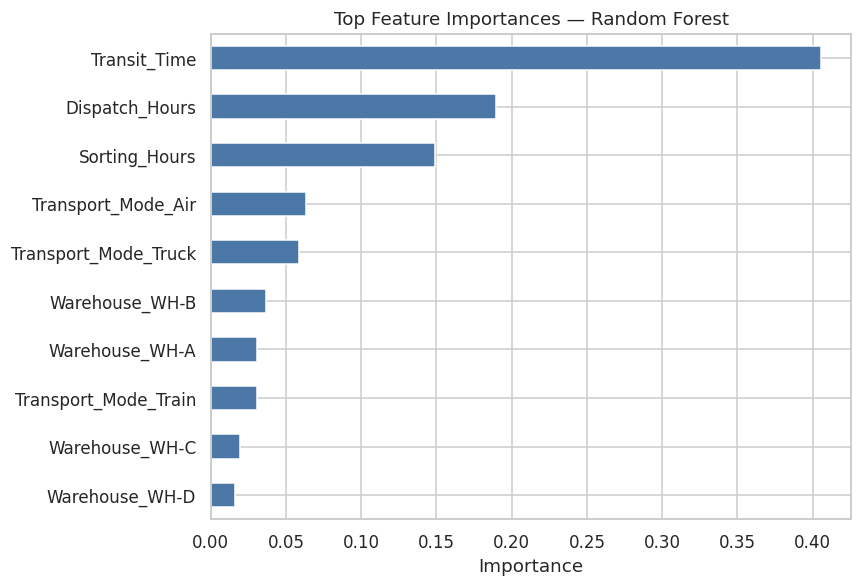

Transit_Time            0.406
Dispatch_Hours          0.189
Sorting_Hours           0.149
Transport_Mode_Air      0.063
Transport_Mode_Truck    0.059
Warehouse_WH-B          0.037
Warehouse_WH-A          0.031
Transport_Mode_Train    0.030
Warehouse_WH-C          0.019
Warehouse_WH-D          0.016
dtype: float64


In [28]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 5.5))
imp.head(12).sort_values().plot(kind="barh", color="#4C78A8")
plt.title("Top Feature Importances — Random Forest")
plt.xlabel("Importance"); plt.tight_layout(); plt.show()

print(imp.head(10).round(3))

In [29]:
# Business use: risk-score shipments and see how many delays the top-risk group captures
test_res = X_test.copy()
test_res["Actual"] = y_test.values
test_res["Risk"] = y_prob
test_res = test_res.sort_values("Risk", ascending=False)
top = test_res.head(int(len(test_res)*0.25))
print(f"Flagging the top 25% highest-risk shipments captures {top['Actual'].sum()/test_res['Actual'].sum()*100:.0f}% of all delays "
      f"(delay rate in that group: {top['Actual'].mean()*100:.0f}% vs {test_res['Actual'].mean()*100:.0f}% overall).")

Flagging the top 25% highest-risk shipments captures 28% of all delays (delay rate in that group: 30% vs 26% overall).


## 9. Practical Action Plan

| Priority | Action | Target | Expected impact |
|---|---|---|---|
| **1 – High** | **Process audit and redesign at WH-C** (sorting layout, staffing shifts, dock scheduling, scanning/automation); copy WH-A's standard operating procedures | Cut WH-C sorting + dispatch from ~21.6 h to ≤ 15 h in 3 months | Lower WH-C delay rate towards the network average and remove the biggest single bottleneck |
| **2 – High** | **Shift long or time-critical lanes from Truck to Train/Air**, especially for the worst lanes (Hyderabad → Coimbatore, Bangalore → Chennai) | Reduce Truck share on high-delay lanes; keep Air for priority parcels | Truck delay rate is 30% vs 15% for Air, so every shifted shipment cuts delay risk |
| **3 – Medium** | **Set stage-level SLAs and live dashboards** (sorting ≤ 8 h, dispatch ≤ 8 h per warehouse) with alerts when a parcel exceeds its stage limit | Alert at the 75th percentile of processing time | Problems are caught inside the warehouse instead of after delivery |
| **4 – Medium** | **Improve WH-B dispatch and sorting**, since it generates the most delays by count | Bring WH-B close to WH-A's ~11 h processing time | Removes about a third of all delays |
| **5 – Medium** | **Deploy the Random Forest as a risk-ranking tool**: score each shipment at dispatch and give the riskiest 25% priority handling or an early customer notification | Weekly monitoring of recall and AUC | Proactive handling of the shipments most likely to be late |
| **6 – Low** | **Carrier and route review for road transit** (driver scheduling, route optimisation, buffer times on 40+ hour trips) | Reduce transit variance | Attacks the 68% of journey time spent in transit |
| **7 – Low** | **Do not invest in extra warehouse capacity purely because of volume**; first fix process efficiency | Re-test the volume effect quarterly | Avoids spending on capacity that the data shows is not the constraint |
| **8 – Data** | **Collect richer data** (weather, traffic, staffing, load/parcel size, carrier ID, exact delay reasons) | New fields in the shipment log | Better model accuracy and root-cause analysis |